In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from itertools import combinations

plt.style.use("seaborn-v0_8")

df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

df.shape

(6267, 44)

In [9]:
#creando dataframe solo con los planetas que tienen metalicidad estelar y radio
df_met = df[
    df["st_met"].notna() &
    df["pl_rade"].notna() &
    (df["clase_radio"] != "sin_dato")
].copy()

df_met.shape

(5600, 44)

In [10]:
n_por_clase = df_met["clase_radio"].value_counts().reset_index()
n_por_clase.columns = ["clase_radio", "N"]

n_por_clase

,clase_radio,N
0,neptuniano,2160
1,gigante_gaseoso,1538
2,supertierra,1138
3,terrestre,543
4,mayor_que_jupiter,221


In [13]:
#agrupar los planetas de acuerdo a la clase de radio 

orden_clases = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

#calcular estadisticas descriptivas de la metalicidad de la estrella

tabla_met_clase = (
    df_met
    .groupby("clase_radio")["st_met"]
    .agg(
        N="count",
        mediana="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        minimo="min",
        maximo="max"
    )
    .reindex(orden_clases)
)

#medir dispersiíon central (para no centrarse en los valores exxtremos)

tabla_met_clase["IQR"] = tabla_met_clase["Q3"] - tabla_met_clase["Q1"]

tabla_met_clase = tabla_met_clase[
    ["N", "mediana", "Q1", "Q3", "IQR", "minimo", "maximo"]
].round(3)

tabla_met_clase

,N,mediana,Q1,Q3,IQR,minimo,maximo
clase_radio,,,,,,,
terrestre,543,-0.02,-0.130,0.053,0.183,-0.56,0.410
supertierra,1138,0.00,-0.100,0.070,0.170,-0.95,0.560
neptuniano,2160,0.01,-0.080,0.100,0.180,-0.92,0.486
gigante_gaseoso,1538,0.10,-0.030,0.220,0.250,-1.00,0.790
mayor_que_jupiter,221,0.05,-0.055,0.176,0.231,-0.56,0.432


In [12]:
tabla_met_clase.to_csv("../tables/tabla_metalicidad_por_clase_radio.csv")

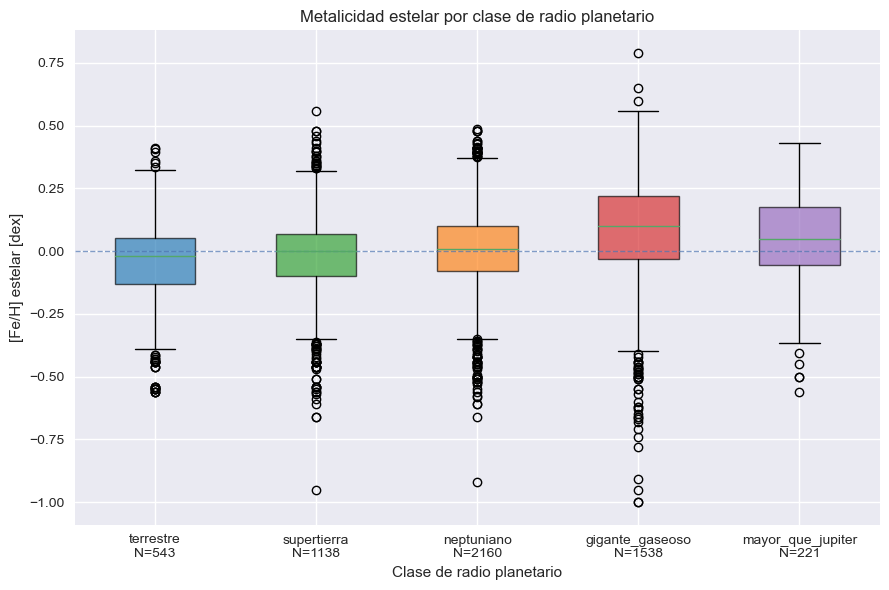

In [7]:
#agrupar los planetas de acuerdo a la clase de radio 
orden_clases = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

labels_con_N = [
    f"{clase}\nN={tabla_met_clase.loc[clase, 'N']}"
    for clase in orden_clases
]

#crear un boxplor de la metalicidad estelar vs la clase de radio, para cada clase de radio

datos_boxplot = [
    df_met[df_met["clase_radio"] == clase]["st_met"].dropna()
    for clase in orden_clases
]

colores = [
    "tab:blue",
    "tab:green",
    "tab:orange",
    "tab:red",
    "tab:purple"
]

plt.figure(figsize=(9, 6))

box = plt.boxplot(
    datos_boxplot,
    labels=labels_con_N,
    patch_artist=True,
    showfliers=True
)

for patch, color in zip(box["boxes"], colores):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

#de acuerdo al planteamiento de [Fe/H], el 0 marca la metalicidad aprox del sol 

plt.axhline(0, linestyle="--", linewidth=1, alpha=0.7)

plt.ylabel("[Fe/H] estelar [dex]")
plt.xlabel("Clase de radio planetario")
plt.title("Metalicidad estelar por clase de radio planetario")

plt.tight_layout()
plt.savefig("../figures/fig_metalicidad_por_clase_radio_boxplot.png", dpi=300)
plt.show()

In [8]:
#ejecutar una prueba kruskal wallis (esta prueva es un anaálisis de varianza pero para grupos)

from scipy.stats import kruskal

grupos_met = [
    df_met[df_met["clase_radio"] == clase]["st_met"].dropna()
    for clase in orden_clases
]

H, p_value = kruskal(*grupos_met)

N_total = sum(len(g) for g in grupos_met)
k = len(grupos_met)

# Tamaño de efecto epsilon cuadrado para Kruskal-Wallis
epsilon_squared = (H - k + 1) / (N_total - k)

tabla_kruskal = pd.DataFrame({
    "prueba": ["Kruskal-Wallis"],
    "variable_dependiente": ["st_met"],
    "grupo": ["clase_radio"],
    "N_total": [N_total],
    "k_grupos": [k],
    "estadistico_H": [H],
    "p_value": [p_value],
    "epsilon_cuadrado": [epsilon_squared]
})

tabla_kruskal.round(6)

,prueba,variable_dependiente,grupo,N_total,k_grupos,estadistico_H,p_value,epsilon_squared
0,Kruskal-Wallis,st_met,clase_radio,5600,5,330.022871,0.0,0.05827


In [19]:
#cocmo se concluyó que al menos dos clases son diferentes se realiza una comparacion por pares
#https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html


from scipy.stats import mannwhitneyu
from itertools import combinations

#todas las combinaciones posibles
pares = list(combinations(orden_clases, 2))

resultados_posthoc = []

for clase_1, clase_2 in pares:
    grupo_1 = df_met[df_met["clase_radio"] == clase_1]["st_met"].dropna()
    grupo_2 = df_met[df_met["clase_radio"] == clase_2]["st_met"].dropna()
    
    U, p = mannwhitneyu(grupo_1, grupo_2, alternative="two-sided")
    
    n1 = len(grupo_1)
    n2 = len(grupo_2)
    
    # Tamaño de efecto rank-biserial correlation
    r_rb = 1 - (2 * U) / (n1 * n2)
    
    resultados_posthoc.append({
        "clase_1": clase_1,
        "clase_2": clase_2,
        "N_1": n1,
        "N_2": n2,
        "mediana_1": grupo_1.median(),
        "mediana_2": grupo_2.median(),
        "diferencia_mediana": grupo_2.median() - grupo_1.median(),
        "U": U,
        "p_value": p,
        "rank_biserial": r_rb
    })

posthoc = pd.DataFrame(resultados_posthoc)

# Corrección para comparaciones múltiples
posthoc = posthoc.sort_values("p_value").reset_index(drop=True)
m = len(posthoc)

posthoc["p_holm"] = [
    min((m - i) * p, 1.0)
    for i, p in enumerate(posthoc["p_value"])
]

posthoc["significativo_holm"] = posthoc["p_holm"] < 0.05

posthoc.round(5)

,clase_1,clase_2,N_1,N_2,mediana_1,mediana_2,diferencia_mediana,U,p_value,rank_biserial,p_holm,significativo_holm
0,supertierra,gigante_gaseoso,1138,1538,0.00,0.10,0.10,591187.5,0.00000,0.32445,0.00000,True
1,neptuniano,gigante_gaseoso,2160,1538,0.01,0.10,0.09,1226802.5,0.00000,0.26143,0.00000,True
2,terrestre,gigante_gaseoso,543,1538,-0.02,0.10,0.12,257397.0,0.00000,0.38358,0.00000,True
3,terrestre,mayor_que_jupiter,543,221,-0.02,0.05,0.07,42712.5,0.00000,0.28814,0.00000,True
4,terrestre,neptuniano,543,2160,-0.02,0.01,0.03,495469.0,0.00000,0.15512,0.00000,True
5,supertierra,mayor_que_jupiter,1138,221,0.00,0.05,0.05,98342.5,0.00000,0.21795,0.00000,True
6,neptuniano,mayor_que_jupiter,2160,221,0.01,0.05,0.04,202860.0,0.00023,0.15008,0.00093,True
7,supertierra,neptuniano,1138,2160,0.00,0.01,0.01,1143577.0,0.00101,0.06954,0.00302,True
8,terrestre,supertierra,543,1138,-0.02,0.00,0.02,281896.0,0.00362,0.08762,0.00724,True
9,gigante_gaseoso,mayor_que_jupiter,1538,221,0.10,0.05,-0.05,190332.0,0.00389,-0.11994,0.00389,True


In [17]:
posthoc.to_csv("../tables/tabla_posthoc_metalicidad_clase_radio.csv", index=False)
tabla_kruskal.to_csv("../tables/tabla_kruskal_metalicidad_clase_radio.csv", index=False)

In [18]:
from scipy.stats import spearmanr

df_spearman_total = df_met[
    df_met["st_met"].notna() &
    df_met["pl_rade"].notna()
].copy()

rho_total, p_total = spearmanr(
    df_spearman_total["st_met"],
    df_spearman_total["pl_rade"]
)

print(f"N = {len(df_spearman_total)}")
print(f"Spearman rho = {rho_total:.4f}")
print(f"p-value = {p_total:.3e}")

N = 5600
Spearman rho = 0.2308
p-value = 1.374e-68


In [20]:
df_spearman_pequenos = df_met[
    df_met["st_met"].notna() &
    df_met["pl_rade"].notna() &
    (df_met["pl_rade"] < 2.0)
].copy()

rho_pequenos, p_pequenos = spearmanr(
    df_spearman_pequenos["st_met"],
    df_spearman_pequenos["pl_rade"]
)

print(f"N = {len(df_spearman_pequenos)}")
print(f"Spearman rho = {rho_pequenos:.4f}")
print(f"p-value = {p_pequenos:.3e}")

N = 1681
Spearman rho = 0.0516
p-value = 3.454e-02


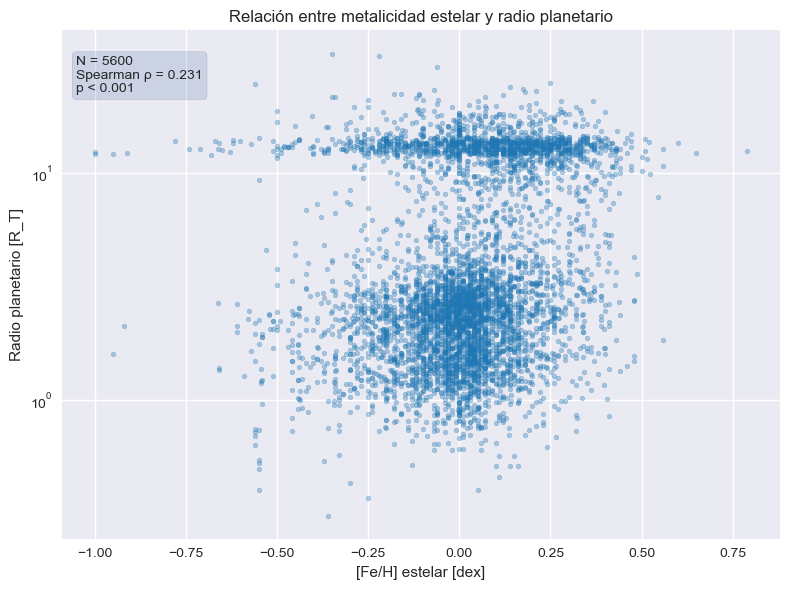

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_spearman_total["st_met"],
    df_spearman_total["pl_rade"],
    s=12,
    alpha=0.35,
    color="tab:blue"
)

plt.yscale("log")

plt.xlabel("[Fe/H] estelar [dex]")
plt.ylabel("Radio planetario [R_T]")
plt.title("Relación entre metalicidad estelar y radio planetario")

plt.text(
    0.02,
    0.95,
    f"N = {len(df_spearman_total)}\nSpearman ρ = {rho_total:.3f}\np < 0.001",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.savefig("../figures/fig_spearman_metalicidad_radio_muestra_completa.png", dpi=300)
plt.show()

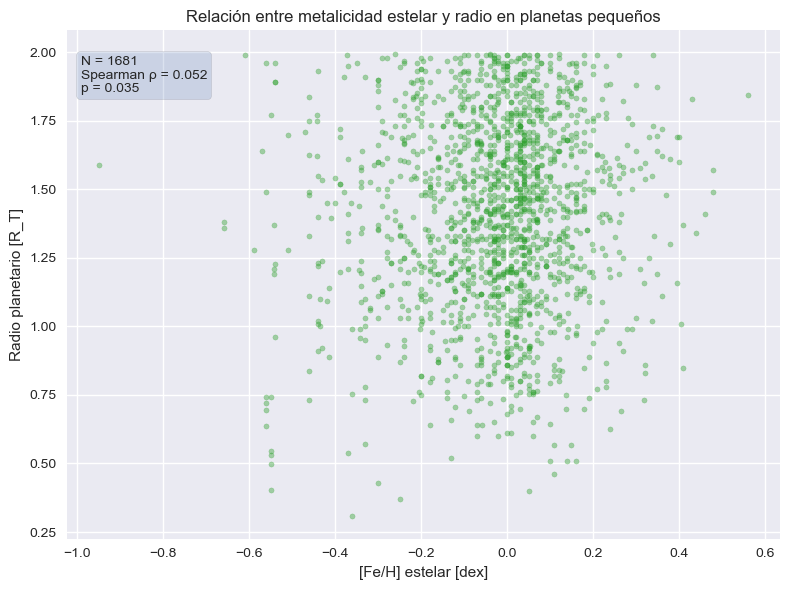

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_spearman_pequenos["st_met"],
    df_spearman_pequenos["pl_rade"],
    s=14,
    alpha=0.4,
    color="tab:green"
)

plt.xlabel("[Fe/H] estelar [dex]")
plt.ylabel("Radio planetario [R_T]")
plt.title("Relación entre metalicidad estelar y radio en planetas pequeños")

plt.text(
    0.02,
    0.95,
    f"N = {len(df_spearman_pequenos)}\nSpearman ρ = {rho_pequenos:.3f}\np = {p_pequenos:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.savefig("../figures/fig_spearman_metalicidad_radio_planetas_pequenos.png", dpi=300)
plt.show()